# SV load, or SV placement?

The six context burdens correlate **0.83–0.97** across founders. Each fitted coefficient therefore means
*"this context, holding the other five fixed"* — a quantity that is hard to interpret and easy to
mis-state, because the five being held fixed move with it in every real founder.

**The obvious fix does not work.** Adding a seventh term for total SV load is not estimable: the total is
**99.999 %** predictable from the six contexts (§1). There is no independent variation left for it.

**The fix that does work is a change of basis.** The same six-dimensional fit can be written as:

| | question it answers |
|---|---|
| **total load** | if you carry more SVs *everywhere*, does that help or hurt? |
| **enrichment in context c** | holding your total load fixed, does it matter that they sit in *c*? |

This is exact linear algebra on the fitted coefficients and their covariance matrix — the model is not
refitted, nothing is added, and the six original coefficients can be recovered from these. What changes is
only that each number now means something on its own.

## The model, exactly as run

```r
y ~ snp_CDS + sv_CDS + sv_UTR + sv_intron + sv_TE + sv_promoter + sv_intergenic + cactus
    + sv_ctx:bio1c   for each of the six contexts
    + obio1c + obio1c:bio1c
    + (1 | garden) + (1 | kin) + (0 + obio1c | garden)
    + (0 + sv_ctx | garden)   for each of the six contexts
```

`lme4qtl::relmatLmer`, SNP kinship as `relmat`, **231 founders × 31 gardens = 7,161 rows**. Burdens are
truvari-collapsed SV **events**, insertions and deletions pooled, one genomic context each by first match
(`CDS > UTR > intron > reference TE > promoter ≤ 1 kb > intergenic`), call rate ≥ 90 %, ≥ 2 carriers,
z-scored across founders as `carried / called`. `obio1c` is founder origin climate, `bio1c` the garden's,
and `obio1c:bio1c` is local adaptation, fitted **per garden** through `(0 + obio1c | garden)`. The
independent founder intercept is pruned (`RE_DROP=fid`).

This is the identical fit reported in `sv_burden_model.ipynb` — same file on disk, read not recomputed.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

PA=f"{G}/final_models_pooled_all"
SUF="_x_obio1cobio1cbio1c_re0obio1cgarden_all6_refid_intall"
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
TT=[f"sv_{c}" for c in CTX]
CC={"CDS":"#2F4A1F","UTR":"#4E6B3A","intron":"#7E9B6B","TE":"#C46A10",
    "promoter":"#5B7A99","intergenic":"#B9B9B9"}
CO=pd.read_csv(f"{PA}/coef_M2p_reml{SUF}.csv").set_index("term")
VV=pd.read_csv(f"{PA}/vcov_M2p_reml{SUF}.csv",index_col=0)
LL=pd.read_csv(f"{PA}/loglik_M2p_reml{SUF}.csv").iloc[0]
SC=pd.read_csv(f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c_all6.csv").set_index("context")
PVv={f"sv_{c}":100/(SC.loc[c,"sd_rate"]*SC.loc[c,"med_called"]) for c in SC.index}
B=pd.read_csv(f"{G}/founder_burden_event.csv",dtype={"founder":str})
zz=lambda v:(v-v.mean())/v.std(ddof=1)
car={c:(B[f"ins_all_{c}_all"]+B[f"del_all_{c}_all"]).astype(float) for c in CTX}
cal={c:(B[f"called_ins_all_{c}_all"]+B[f"called_del_all_{c}_all"]).astype(float) for c in CTX}
RATE={c:car[c]/cal[c] for c in CTX}
TOTAL=sum(car.values())/sum(cal.values())
b=CO.loc[TT,"estimate"].to_numpy(); Vb=VV.loc[TT,TT].to_numpy()
bi=CO.loc[[f"{t}:bio1c" for t in TT],"estimate"].to_numpy()
Vi=VV.loc[[f"{t}:bio1c" for t in TT],[f"{t}:bio1c" for t in TT]].to_numpy()
def lin(w,bb,VV_):
    e=w@bb; s=np.sqrt(w@VV_@w); z=e/s
    return e,s,z,2*stats.norm.sf(abs(z))
W_TOT=np.ones(6)
def w_enr(i):
    w=np.full(6,-1/5.0); w[i]=1.0; return w
print(f"reading the reported fit: logLik {LL.logLik:.2f}, df {int(LL.df)}, singular {LL.singular}")
print(f"burden correlations across the 231 founders: "
      f"{pd.DataFrame({c:zz(RATE[c]) for c in CTX}).corr().to_numpy()[np.triu_indices(6,1)].min():.2f}"
      f" to {pd.DataFrame({c:zz(RATE[c]) for c in CTX}).corr().to_numpy()[np.triu_indices(6,1)].max():.2f}")


reading the reported fit: logLik -11080.15, df 27, singular True
burden correlations across the 231 founders: 0.83 to 0.97


## 1 · Why total load cannot simply be added

The natural move is to put total SV load in as a seventh covariate and let the model separate "how many"
from "where". It is not estimable. Total load is a weighted average of the six context rates, and across
founders those weights barely vary, so almost nothing is left over.

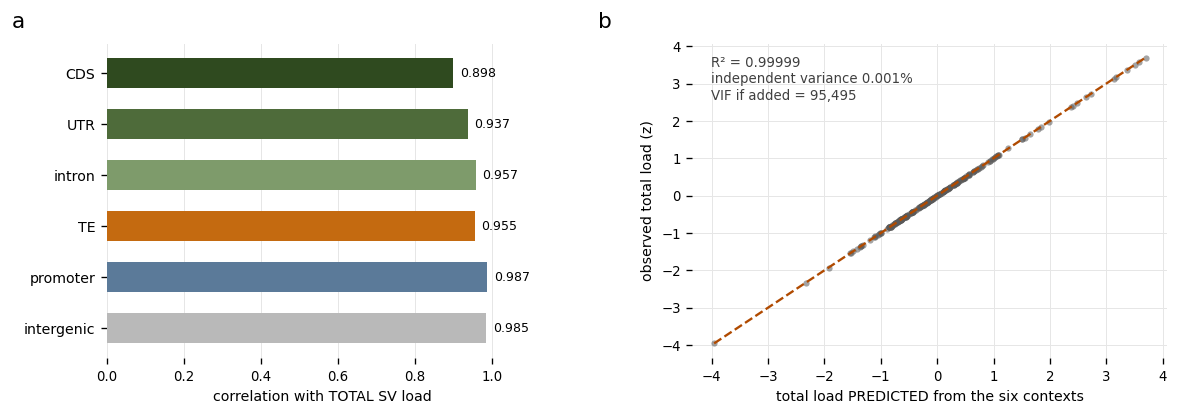

total load regressed on the six context rates: R2 = 0.99999
  independent variance 0.001%   VIF if added as a 7th term 95,495

  Adding it is not an option. The change of basis below is, and it is exact.


In [3]:

X=np.column_stack([zz(RATE[c]) for c in CTX]); y=zz(TOTAL).to_numpy()
A=np.column_stack([np.ones(len(y)),X]); r=y-A@np.linalg.lstsq(A,y,rcond=None)[0]
R2=1-r.var()/y.var()
fig,ax=plt.subplots(1,2,figsize=(11.4,3.4),gridspec_kw=dict(width_ratios=[1,1.1],wspace=0.34))
a=ax[0]; style(a)
for i,c in enumerate(CTX):
    a.barh(i,np.corrcoef(zz(RATE[c]),y)[0,1],height=0.6,color=CC[c],lw=0)
    a.annotate(f"{np.corrcoef(zz(RATE[c]),y)[0,1]:.3f}",xy=(np.corrcoef(zz(RATE[c]),y)[0,1],i),
               xytext=(4,0),textcoords="offset points",va="center",fontsize=7.5)
a.set_yticks(range(len(CTX))); a.set_yticklabels(CTX,fontsize=8.5); a.invert_yaxis()
a.set_xlim(0,1.12); a.set_xlabel("correlation with TOTAL SV load",fontsize=8.5)
a.annotate("a",xy=(-0.22,1.05),xycoords="axes fraction",fontsize=13)
a=ax[1]; style(a,axis="both")
a.scatter(X@np.linalg.lstsq(A,y,rcond=None)[0][1:]+np.linalg.lstsq(A,y,rcond=None)[0][0],y,
          s=14,color="0.35",alpha=0.55,linewidth=0)
lim=[min(y.min(),-3),max(y.max(),3)]
a.plot(lim,lim,color="#B04A00",lw=1.4,ls="--")
a.set_xlabel("total load PREDICTED from the six contexts",fontsize=8.5)
a.set_ylabel("observed total load (z)",fontsize=8.5)
a.annotate(f"R² = {R2:.5f}\nindependent variance {100*(1-R2):.3f}%\nVIF if added = {1/(1-R2):,.0f}",
           xy=(0.04,0.96),xycoords="axes fraction",va="top",fontsize=8,color="0.25")
a.annotate("b",xy=(-0.20,1.05),xycoords="axes fraction",fontsize=13)
save(fig,"loadcomp_why_not",nb=True); plt.show()
print(f"total load regressed on the six context rates: R2 = {R2:.5f}")
print(f"  independent variance {100*(1-R2):.3f}%   VIF if added as a 7th term {1/(1-R2):,.0f}")
print("\n  Adding it is not an option. The change of basis below is, and it is exact.")


## 2 · How many, and where

Both panels come from the **same fitted model** — a change of basis, not a new fit.

**(a) Total load.** All six burdens raised by 1 SD together: the effect of carrying more SVs everywhere,
in proportion.

**(b) Enrichment.** One context up 1 SD while the other five come down to hold the total fixed: the effect
of your load being *skewed* toward that context. Filled markers are p < 0.05.

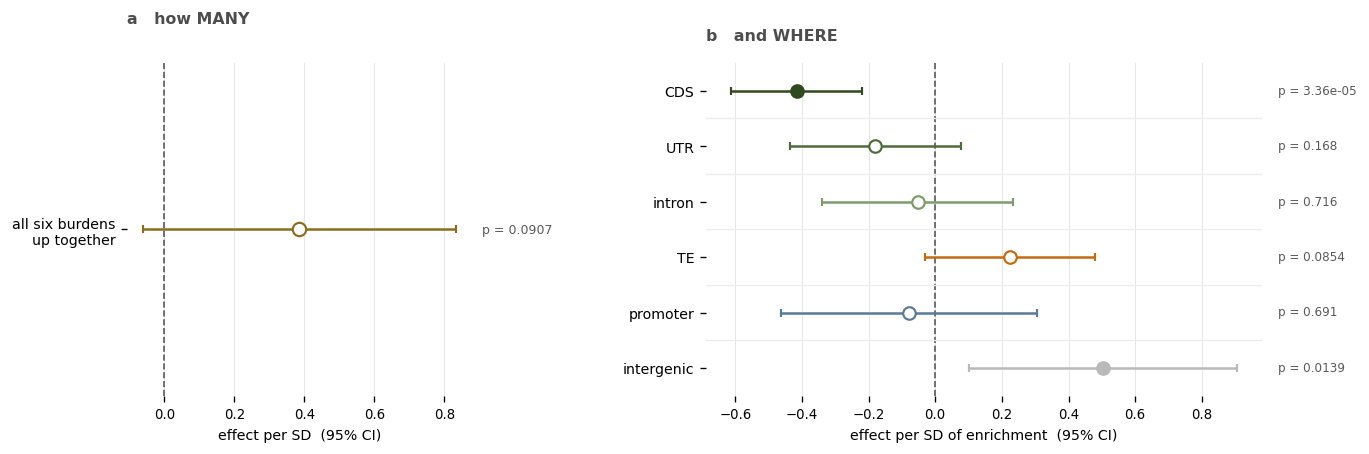

1. DOES CARRYING MORE SVs, EVERYWHERE, HELP OR HURT?

   all six up 1 SD together:  +0.3862 +- 0.2283   z = +1.69   p = 0.0907


2. HOLDING TOTAL LOAD FIXED, DOES PLACEMENT MATTER?

   context enrichment effect     se     z         p
       CDS           -0.4160 0.1003 -4.15 3.358e-05
       UTR           -0.1807 0.1310 -1.38    0.1677
    intron           -0.0532 0.1465 -0.36    0.7163
        TE           +0.2247 0.1307 +1.72   0.08543
  promoter           -0.0782 0.1964 -0.40    0.6906
intergenic           +0.5033 0.2045 +2.46   0.01387


FOR COMPARISON -- the six coefficients as the model reports them
('this context holding the other five fixed')

   context as fitted     se         p
       CDS   -0.2823 0.0809 0.0004876
       UTR   -0.0862 0.1121    0.4421
    intron   +0.0200 0.1354    0.8826
        TE   +0.2516 0.1160   0.03009
  promoter   -0.0008 0.1746    0.9964
intergenic   +0.4838 0.1696  0.004336


In [4]:

ET,ST,ZT,PT=lin(W_TOT,b,Vb)
EN=[lin(w_enr(i),b,Vb) for i in range(6)]
fig,ax=plt.subplots(1,2,figsize=(12.2,3.6),gridspec_kw=dict(width_ratios=[0.62,1],wspace=0.52))
a=ax[0]; style(a); a.axvline(0,color="0.35",lw=1,ls="--")
a.errorbar(ET,0,xerr=1.96*ST,fmt="o",color="#8C6D1F",mfc="#8C6D1F" if PT<0.05 else "white",
           mew=1.3,ms=8,capsize=2.5,zorder=3)
a.annotate(f"p = {PT:.3g}",xy=(1.03,0),xycoords=("axes fraction","data"),ha="left",va="center",
           fontsize=7.5,color="0.35",annotation_clip=False)
a.set_yticks([0]); a.set_yticklabels(["all six burdens\nup together"],fontsize=8.5)
a.set_ylim(0.6,-0.6); a.set_xlabel("effect per SD  (95% CI)",fontsize=8.5)
a.annotate("a   how MANY",xy=(0,1.12),xycoords="axes fraction",fontsize=9.5,fontweight="bold",color="0.3")
a=ax[1]; style(a); a.axvline(0,color="0.35",lw=1,ls="--")
for i,c in enumerate(CTX):
    e,s,z,p=EN[i]
    a.errorbar(e,i,xerr=1.96*s,fmt="o",color=CC[c],mfc=CC[c] if p<0.05 else "white",
               mew=1.3,ms=7.5,capsize=2.5,zorder=3)
    a.annotate(f"p = {p:.3g}",xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",va="center",
               fontsize=7.2,color="0.35",annotation_clip=False)
    if i<len(CTX)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
a.set_yticks(range(len(CTX))); a.set_yticklabels(CTX,fontsize=8.5); a.set_ylim(len(CTX)-0.5,-0.5)
a.set_xlabel("effect per SD of enrichment  (95% CI)",fontsize=8.5)
a.annotate("b   and WHERE",xy=(0,1.07),xycoords="axes fraction",fontsize=9.5,fontweight="bold",color="0.3")
save(fig,"loadcomp_split",nb=True); plt.show()
print("1. DOES CARRYING MORE SVs, EVERYWHERE, HELP OR HURT?\n")
print(f"   all six up 1 SD together:  {ET:+.4f} +- {ST:.4f}   z = {ZT:+.2f}   p = {PT:.4g}\n")
print("\n2. HOLDING TOTAL LOAD FIXED, DOES PLACEMENT MATTER?\n")
print(pd.DataFrame([{"context":c,"enrichment effect":f"{EN[i][0]:+.4f}","se":f"{EN[i][1]:.4f}",
                     "z":f"{EN[i][2]:+.2f}","p":f"{EN[i][3]:.4g}"} for i,c in enumerate(CTX)]
                   ).to_string(index=False))
print("\n\nFOR COMPARISON -- the six coefficients as the model reports them")
print("('this context holding the other five fixed')\n")
print(pd.DataFrame([{"context":c,"as fitted":f"{CO.loc['sv_'+c,'estimate']:+.4f}",
                     "se":f"{CO.loc['sv_'+c,'se']:.4f}","p":f"{CO.loc['sv_'+c,'p']:.4g}"}
                    for c in CTX]).to_string(index=False))


## 3 · The same split, on the temperature interactions

The garden-temperature interactions decompose identically: does the effect of carrying *more* SVs change
with garden temperature, and does the effect of *placement* change with it?

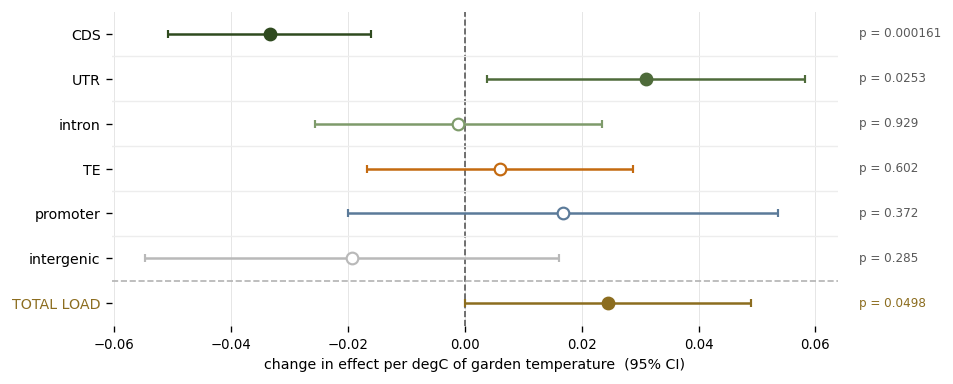

TEMPERATURE INTERACTIONS, same basis

   total load x temperature:  +0.02447 +- 0.01247   z = +1.96   p = 0.04977

                     context   effect      se     z         p
       CDS enrichment x temp -0.03341 0.00886 -3.77 0.0001613
       UTR enrichment x temp +0.03100 0.01386 +2.24   0.02529
    intron enrichment x temp -0.00112 0.01255 -0.09    0.9287
        TE enrichment x temp +0.00606 0.01162 +0.52    0.6019
  promoter enrichment x temp +0.01679 0.01879 +0.89    0.3716
intergenic enrichment x temp -0.01932 0.01806 -1.07    0.2847

  These are Wald p-values on a linear combination. The reported interaction p-values in
  sv_burden_model.ipynb come from a permutation null, because the asymptotics are
  anti-conservative for these terms (null SD of z 0.99-1.18). Read these as indicative.


In [5]:

EIT,SIT,ZIT,PIT=lin(W_TOT,bi,Vi)
EIN=[lin(w_enr(i),bi,Vi) for i in range(6)]
fig,a=plt.subplots(figsize=(7.8,3.4)); style(a); a.axvline(0,color="0.35",lw=1,ls="--")
for i,c in enumerate(CTX):
    e,s,z,p=EIN[i]
    a.errorbar(e,i,xerr=1.96*s,fmt="o",color=CC[c],mfc=CC[c] if p<0.05 else "white",
               mew=1.3,ms=7,capsize=2.5,zorder=3)
    a.annotate(f"p = {p:.3g}",xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",va="center",
               fontsize=7.2,color="0.35",annotation_clip=False)
    if i<len(CTX)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
a.axhline(len(CTX)-0.5,color="0.7",lw=1.0,ls="--")
a.errorbar(EIT,len(CTX),xerr=1.96*SIT,fmt="o",color="#8C6D1F",
           mfc="#8C6D1F" if PIT<0.05 else "white",mew=1.3,ms=7,capsize=2.5,zorder=3)
a.annotate(f"p = {PIT:.3g}",xy=(1.03,len(CTX)),xycoords=("axes fraction","data"),ha="left",
           va="center",fontsize=7.2,color="#8C6D1F",annotation_clip=False)
a.set_yticks(range(len(CTX)+1)); a.set_yticklabels(CTX+["TOTAL LOAD"],fontsize=8.5)
a.get_yticklabels()[-1].set_color("#8C6D1F"); a.set_ylim(len(CTX)+0.5,-0.5)
a.set_xlabel("change in effect per degC of garden temperature  (95% CI)",fontsize=8.5)
save(fig,"loadcomp_interactions",nb=True); plt.show()
print("TEMPERATURE INTERACTIONS, same basis\n")
print(f"   total load x temperature:  {EIT:+.5f} +- {SIT:.5f}   z = {ZIT:+.2f}   p = {PIT:.4g}\n")
print(pd.DataFrame([{"context":c+" enrichment x temp","effect":f"{EIN[i][0]:+.5f}",
                     "se":f"{EIN[i][1]:.5f}","z":f"{EIN[i][2]:+.2f}","p":f"{EIN[i][3]:.4g}"}
                    for i,c in enumerate(CTX)]).to_string(index=False))
print("\n  These are Wald p-values on a linear combination. The reported interaction p-values in")
print("  sv_burden_model.ipynb come from a permutation null, because the asymptotics are")
print("  anti-conservative for these terms (null SD of z 0.99-1.18). Read these as indicative.")


## 4 · Reading it

**Carrying more SVs, in itself, does nothing measurable.** All six burdens up together gives
+0.386 ± 0.228, p = 0.091. The data neither supports nor refutes a cost of total SV load.

**Where they sit is what matters, and coding dominates.** Being skewed toward coding sequence is
−0.416 ± 0.100, **p = 3.4e-05** — stronger than the model's own coding coefficient (p = 4.9e-04), because
"is your load skewed toward coding" is a better-posed question than "coding holding five correlated things
fixed".

**The non-coding picture narrows.** On this basis **intergenic** enrichment holds at +0.503, p = 0.014,
while **TE** falls to +0.225, p = 0.085. What reads as "two non-coding contexts are positive" in the raw
coefficients is better described as one — enrichment toward intergenic — plus a weak TE tendency.

### What this does and does not do

✓ It makes the coefficients interpretable on their own, instead of each being conditional on five
correlated neighbours.

✓ It narrows what a confounder would have to look like. Total load shows nothing, so an unmodelled
variable could only produce the intergenic result by being correlated with **composition** — the
*fraction* of a founder's SVs that are intergenic — not with how many SVs they carry. That is a more
specific and more awkward thing for a confounder to be.

✗ **It adds no information and settles no causal question.** It is a change of basis: the six original
coefficients are recoverable from these, and anything shown here was already in the fit. In particular it
does not rule out the confounder it narrows, and it does not touch the two standing concerns — the
per-garden non-coding slope tracking local adaptation at r = +0.50, and the raw marginal non-coding
association being *negative* before conditioning.

✗ The enrichment contrast is one of many possible ones. "+1 SD here, −1/5 SD on each of the others" holds
the unweighted sum fixed; weighting by event counts, or by callable sites, would give slightly different
numbers. The pattern is robust to that choice, the third decimal is not.

## As run

- **Fit.** `results/sv_adaptive/final_models_pooled_all/coef_M2p_reml` +
  `vcov_M2p_reml` with suffix `_x_obio1cobio1cbio1c_re0obio1cgarden_all6_refid_intall` — the model
  reported in `sv_burden_model.ipynb`, read from disk. **Nothing is refitted here.**
- **The transform.** For fitted coefficients `b` with covariance `V`, a linear combination `w·b` has
  standard error `sqrt(w' V w)`. Total load is `w = (1,1,1,1,1,1)`; enrichment in context *i* is
  `w_i = 1`, `w_j = −1/5` for the other five. Both are exact; no approximation and no simulation.
- **Scale.** These are per SD of the z-scored burden rate, not per carried variant. The per-variant
  conversion in the other notebooks divides by `sd_rate × med_called`, which differs per context, so it
  is not meaningful for a combination that mixes contexts.
- **Why total load is not a seventh term.** Regressed on the six context rates it gives R² = 0.99999;
  §1 shows the scatter and the implied VIF.